# SafeOps — Safe Route Prediction: Weighted KDE Risk Surface

Clean, consolidated notebook. Committed methodology: **Weighted Kernel Density Estimation (KDE)** over the Karnataka FIR dataset, using severity- and recency-weighted historical crime points, to estimate spatial risk at any coordinate — feeding eventual OSM road-segment scoring and Dijkstra routing.

Random Forest was tried and rejected (see project handoff doc). This notebook does not include any Random Forest code.

In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

## Stage 1 — Load data, deduplicate, validate coordinates

Loads the raw Karnataka FIR CSV, drops exact-duplicate rows, and nulls out any coordinate outside Karnataka's real geographic bounding box (impossible values like lat=131 are data-entry corruption, not real locations).

In [2]:
DATA_PATH = "/kaggle/input/datasets/vanshangaria/fir-details-karnataka-police/FIR_Details_Data.csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(list(df.columns))

/tmp/ipykernel_16/2880096671.py:2: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


Shape: (1674734, 34)

Columns:
['District_Name', 'UnitName', 'FIR_YEAR', 'FIR_MONTH', 'Offence_Duration', 'FIR_Day', 'FIR Type', 'FIR_Stage', 'Complaint_Mode', 'CrimeGroup_Name', 'CrimeHead_Name', 'Latitude', 'Longitude', 'ActSection', 'IOName', 'KGID', 'Internal_IO', 'Place of Offence', 'Distance from PS', 'Beat_Name', 'Village_Area_Name', 'Male', 'Female', 'Boy', 'Girl', 'Age 0', 'VICTIM COUNT', 'Accused Count', 'Arrested Male', 'Arrested Female', 'Arrested Count\tNo.', 'Accused_ChargeSheeted Count', 'Conviction Count', 'Unit_ID']


In [3]:
print("Rows before dedup:", len(df))
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after dedup:", len(df))

Rows before dedup: 1674734
Rows after dedup: 1651937


In [4]:
KA_LAT_MIN, KA_LAT_MAX, KA_LON_MIN, KA_LON_MAX = 11.5, 18.5, 74.0, 78.6

has_coords = df['Latitude'].notna() & df['Longitude'].notna()
valid_box = df['Latitude'].between(KA_LAT_MIN, KA_LAT_MAX) & df['Longitude'].between(KA_LON_MIN, KA_LON_MAX)

print("Rows with any lat/lon:", has_coords.sum())
print("Rows with corrupted lat/lon (out of Karnataka box):", (has_coords & ~valid_box).sum())

# Null out corrupted coordinates rather than trusting them
df.loc[has_coords & ~valid_box, ['Latitude', 'Longitude']] = np.nan

Rows with any lat/lon: 507447
Rows with corrupted lat/lon (out of Karnataka box): 20975


## Stage 2 — Date reconstruction + exclude online/cyber crime rows

Online/cyber-crime FIRs have no physical location and are irrelevant to a road-route safety model, so they're excluded before anything spatial is built. `FIR_Date` is reconstructed for the recency-weighting step later.

In [5]:
df['FIR_Date'] = pd.to_datetime(
    dict(year=df['FIR_YEAR'], month=df['FIR_MONTH'], day=df['FIR_Day']),
    errors='coerce'
)
print("Parse failures:", df['FIR_Date'].isna().sum())
print("Date range:", df['FIR_Date'].min(), "to", df['FIR_Date'].max())

Parse failures: 0
Date range: 2016-01-01 00:00:00 to 2024-03-10 00:00:00


In [6]:
is_online_distance = df['Distance from PS'].astype(str).str.contains('online', case=False, na=False)
is_cyber_group = df['CrimeGroup_Name'].astype(str).str.strip().str.upper().str.contains('CYBER', na=False)

print("Rows flagged online (via Distance from PS):", is_online_distance.sum())
print("Rows flagged cyber (via CrimeGroup_Name):", is_cyber_group.sum())
print("Total excluded (either signal):", (is_online_distance | is_cyber_group).sum())

df = df[~(is_online_distance | is_cyber_group)].reset_index(drop=True)
print("Shape after exclusion:", df.shape)

Rows flagged online (via Distance from PS): 32388
Rows flagged cyber (via CrimeGroup_Name): 69429
Total excluded (either signal): 69472
Shape after exclusion: (1582465, 35)


## Stage 3 — Crime-group cleanup + severity tier mapping

Standardizes `CrimeGroup_Name` text, then maps every one of the 105 categories to a 1–4 severity tier (Tier 4 = severe/life-threatening, Tier 1 = low/administrative). This is reasoned domain-knowledge weighting — verified to cover all 105 categories with zero unmapped rows.

`FIR Type` (Heinous/Non-Heinous) was tested earlier and rejected as a severity signal — it tracks completed/fatal outcome, not inherent danger (e.g. Attempt to Murder is only 3.7% Heinous).

In [7]:
df['CrimeGroup_Name'] = df['CrimeGroup_Name'].str.strip().str.upper()
print("Unique CrimeGroup_Name categories:", df['CrimeGroup_Name'].nunique())

Unique CrimeGroup_Name categories: 105


In [8]:
severity_map = {
    # Tier 4 -- severe / life-threatening
    'MURDER': 4, 'ATTEMPT TO MURDER': 4, 'RAPE': 4, 'DACOITY': 4, 'ROBBERY': 4,
    'KIDNAPPING AND ABDUCTION': 4, 'DOWRY DEATHS': 4,
    'CULPABLE HOMICIDE NOT AMOUNTING TO MURDER': 4,
    'ATTEMPT TO CULPABLE HOMICIDE NOT AMOUNTING TO MURDER': 4,
    'POCSO': 4, 'HUMAN TRAFFICKING': 4, 'IMMORAL TRAFFIC': 4, 'SLAVERY': 4,
    'BONDED LABOUR SYSTEM': 4, 'UNNATURAL SEX': 4,
    'ASSAULT OR USE OF CRIMINAL FORCE TO DISROBE WOMAN': 4, 'PORNOGRAPHY': 4,
    'BUYING & SELLING MINOR FOR PROSTITUTION': 4, 'INFANTICIDE': 4,
    'EXPOSURE AND ABANDONMENT OF CHILD': 4,
    'CONCEALMENT OF BIRTH BY SECRET DISPOSAL OF CHILD': 4,
    'EXPLOSIVES': 4, 'ARSON': 4, 'MOTOR VEHICLE ACCIDENTS FATAL': 4,
    'DEATHS DUE TO RASHNESS/NEGLIGENCE': 4, 'DEATHS-MISCARRIAGE': 4,
    'UNNATURAL DEATH (SEC 174/174C/176)': 4, 'POISONING-PROFESSIONAL': 4,
    'UNLAWFUL ACTIVITIES(PREVENTION)ACT 1967': 4, 'SEDITION': 4,
    'NATIONAL SECURITY ACT': 4, 'OFFENCES AGAINST STATE': 4,
    # Tier 3 -- high
    'MOLESTATION': 3, 'RIOTS': 3, 'CRUELTY BY HUSBAND': 3, 'CRIMINAL INTIMIDATION': 3,
    'CRIMES RELATED TO WOMEN': 3, 'SCHEDULED CASTE AND THE SCHEDULED TRIBES': 3,
    'BURGLARY - NIGHT': 3, 'BURGLARY - DAY': 3, 'WRONGFUL RESTRAINT/CONFINEMENT': 3,
    'CASES OF HURT': 3, 'NARCOTIC DRUGS & PSHYCOTROPIC SUBSTANCES': 3,
    'ARMS ACT  1959': 3, 'COMMUNAL / RELIGION': 3,
    'INSULTING MODESTY OF WOMEN (EVE TEASING)': 3, 'OFFENCES PROMOTING ENEMITY': 3,
    'ASSAULT': 3, 'CRIMINAL CONSPIRACY': 3, 'ESCAPE FROM LAWFUL CUSTODY AND RESISTANCE': 3,
    'SUICIDE': 3,
    # Tier 2 -- moderate
    'THEFT': 2, 'CHEATING': 2, 'CRIMINAL TRESPASS': 2, 'MISCHIEF': 2, 'FORGERY': 2,
    'CRIMINAL BREACH OF TRUST': 2, 'COUNTERFEITING': 2, 'AFFRAY': 2, 'PUBLIC NUISANCE': 2,
    'OFFENCES AGAINST PUBLIC SERVANTS (PUBLIC SERVANT IS A VICTIM)': 2,
    'DISOBEDIENCE TO ORDER PROMULGATED BY PUBLICSERVAN': 2,
    'PREVENTION OF DAMAGE TO PUBLIC PROPERTY ACT 1984': 2, 'RECEIVING OF STOLEN PROPERTY': 2,
    'IMPERSONATION': 2, 'CRIMINAL MISAPPROPRIATION': 2, 'DOCUMENTS & PROPERTY MARKS': 2,
    'ANTIQUES (CULTURAL PROPERTY)': 2, 'OF ABETMENT': 2,
    'GIVING FALSE INFORMATION RESPECTING AN OFFENCE COM': 2, 'FALSE EVIDENCE': 2,
    'DEFAMATION': 2, 'ADULTERATION': 2, 'MOTOR VEHICLE ACCIDENTS NON-FATAL': 2,
    'NEGLIGENT ACT': 2, 'INDIAN MOTOR VEHICLE': 2, 'ANIMAL': 2, 'ATTEMPTING TO COMMIT OFFENCES': 2,
    # Tier 1 -- low / administrative
    'CRPC': 1, 'MISSING PERSON': 1, 'KARNATAKA POLICE ACT 1963': 1,
    'KARNATAKA STATE LOCAL ACT': 1, 'PUBLIC SAFETY': 1, 'CONSUMER': 1,
    'COTPA, CIGARETTES AND OTHER TOBACCO PRODUCTS': 1, 'ELECTION': 1, 'CHILDREN ACT': 1,
    'FAILURE TO APPEAR TO COURT': 1, 'COPY RIGHT ACT 1957': 1,
    'REPRESENTATION OF PEOPLE ACT 1951 & 1988': 1, 'FOREIGNER': 1,
    'OFFENCES RELATED TO MARRIAGE': 1, 'PASSPORT ACT': 1, 'INDIAN ELECTRICITY ACT': 1,
    'FOREST': 1, 'OFFENCES BY PUBLIC SERVANTS (EXCEPT CORRUPTION) (PUBLIC SERVANT IS ACCUSED)': 1,
    'RAILWAYS ACT': 1, 'CIVIL RIGHTS': 1, 'OFFICIAL SECURITY RELATED ACTS': 1,
    'PUBLIC JUSTICE': 1, 'POST & TELEGRAPH,TELEGRAPH WIRES(UNLAWFUL POSSESSION)ACT 1950': 1,
    'CINEMATOGRAPH ACT 1952': 1,
    'DEFENCE FORCES OFFENCES RELATING TO (ALSO RELATING TO DESERTION)': 1,
    'PREVENTION OF CORRUPTION ACT 1988': 1, 'ILLEGAL DETENTION': 1,
}

df['Severity_Tier'] = df['CrimeGroup_Name'].map(severity_map)
print("Unmapped categories:", df['Severity_Tier'].isna().sum())
print("\nTier distribution (%):")
print((df['Severity_Tier'].value_counts(normalize=True) * 100).sort_index())

Unmapped categories: 0

Tier distribution (%):
Severity_Tier
1    32.142385
2    32.834723
3    22.645872
4    12.377019
Name: proportion, dtype: float64


## Stage 4 — Recency decay weight + combined Risk_Contribution + fir_points

Exponential time decay (half-life = 2 years, reference year = 2024, the most recent year in the data) so recent crimes count more than old ones. Combined with severity to get `Risk_Contribution` — the per-FIR weight the KDE will use.

`fir_points` is the final, minimal reference table for everything downstream: only real-coordinate rows, only the columns KDE actually needs.

In [9]:
REFERENCE_YEAR = df['FIR_YEAR'].max()
print("Reference year:", REFERENCE_YEAR)

HALF_LIFE = 2  # years
df['Recency_Weight'] = 0.5 ** ((REFERENCE_YEAR - df['FIR_YEAR']) / HALF_LIFE)

print(df[['FIR_YEAR', 'Recency_Weight']].drop_duplicates().sort_values('FIR_YEAR'))

Reference year: 2024
      FIR_YEAR  Recency_Weight
0         2016        0.062500
211       2017        0.088388
406       2018        0.125000
592       2019        0.176777
698       2020        0.250000
832       2021        0.353553
982       2022        0.500000
1109      2023        0.707107
1265      2024        1.000000


In [10]:
df['Risk_Contribution'] = df['Severity_Tier'] * df['Recency_Weight']
print(df['Risk_Contribution'].describe())

count    1.582465e+06
mean     6.504743e-01
std      6.721342e-01
min      6.250000e-02
25%      1.767767e-01
50%      3.535534e-01
75%      1.000000e+00
max      4.000000e+00
Name: Risk_Contribution, dtype: float64


In [11]:
fir_points = df[df['Latitude'].notna() & df['Longitude'].notna()].copy()
fir_points = fir_points[['Latitude', 'Longitude', 'FIR_YEAR', 'CrimeGroup_Name',
                          'Severity_Tier', 'Recency_Weight', 'Risk_Contribution']].reset_index(drop=True)

print("fir_points shape:", fir_points.shape)   # expected: (471001, 7)
print(fir_points.head())
print("\nRisk_Contribution by tier (sanity check - should increase with tier):")
print(fir_points.groupby('Severity_Tier')['Risk_Contribution'].mean())

fir_points shape: (471001, 7)
    Latitude  Longitude  FIR_YEAR                CrimeGroup_Name  \
0  16.054967  75.950667      2019      KARNATAKA POLICE ACT 1963   
1  16.141122  75.910169      2019      KARNATAKA STATE LOCAL ACT   
2  16.135827  75.919221      2019  MOTOR VEHICLE ACCIDENTS FATAL   
3  16.109622  75.931844      2019                          RIOTS   
4  16.109778  75.931920      2019                          RIOTS   

   Severity_Tier  Recency_Weight  Risk_Contribution  
0              1        0.176777           0.176777  
1              1        0.176777           0.176777  
2              4        0.176777           0.707107  
3              3        0.176777           0.530330  
4              3        0.176777           0.530330  

Risk_Contribution by tier (sanity check - should increase with tier):
Severity_Tier
1    0.424957
2    0.860513
3    1.345225
4    1.750054
Name: Risk_Contribution, dtype: float64


### Checkpoint save

`/kaggle/working` resets between Kaggle sessions unless committed via **File -> Save Version -> Save & Run All (Commit)**. Save now, and commit immediately after this cell runs, before continuing — this notebook has already lost a checkpoint once from a session reset.

In [12]:
fir_points.to_csv('/kaggle/working/fir_points.csv', index=False)
print("Saved. Shape:", fir_points.shape)

fir_points_check = pd.read_csv('/kaggle/working/fir_points.csv')
print("Reloaded shape:", fir_points_check.shape)
print("Matches original:", fir_points_check.shape == fir_points.shape)

Saved. Shape: (471001, 7)
Reloaded shape: (471001, 7)
Matches original: True


### Free memory: drop the full 1.5M-row `df` now

Everything downstream only needs `fir_points` (471,001 rows, 7 columns) — not the full dataframe. Dropping `df` here is the single biggest memory saving in this notebook and is what fixes the "Save Version" memory-limit crash.

In [13]:
import gc
del df
gc.collect()
print("df dropped. Remaining large object: fir_points.")

df dropped. Remaining large object: fir_points.


## Stage 6 — Build BallTree spatial index + initial KDE scoring function

The BallTree (haversine metric) lets us efficiently query "all FIRs within X km of this point" instead of computing distance to all 471,001 rows every time. `kde_risk` is an **unnormalized** weighted Gaussian sum — the exact formula from the project handoff doc: `risk(p) = sum_i [ Risk_Contribution_i * Gaussian(distance(p, fir_i) / bandwidth) ]`.

`bandwidth_km=0.5` here is only a placeholder for the first sanity check — the real bandwidth is selected via cross-validation in Stage 8.

In [14]:
from sklearn.neighbors import BallTree

# BallTree with haversine metric needs radians, not degrees
coords_rad = np.radians(fir_points[['Latitude', 'Longitude']].values)
tree = BallTree(coords_rad, metric='haversine')

EARTH_RADIUS_KM = 6371.0

print("BallTree built on", len(fir_points), "points")

BallTree built on 471001 points


In [15]:
def kde_risk(lat, lon, bandwidth_km=0.5, radius_multiplier=3):
    """
    Estimate risk at a single point using weighted Gaussian KDE.
    bandwidth_km: kernel bandwidth (how 'wide' each crime's influence is)
    radius_multiplier: how many bandwidths out we search before treating
                        influence as negligible (3 bandwidths ~ 99.7% of a Gaussian)
    """
    query_rad = np.radians([[lat, lon]])
    search_radius_rad = (bandwidth_km * radius_multiplier) / EARTH_RADIUS_KM

    idx, dist_rad = tree.query_radius(query_rad, r=search_radius_rad, return_distance=True)
    idx, dist_rad = idx[0], dist_rad[0]

    if len(idx) == 0:
        return 0.0

    dist_km = dist_rad * EARTH_RADIUS_KM
    weights = fir_points.iloc[idx]['Risk_Contribution'].values
    kernel_vals = np.exp(-0.5 * (dist_km / bandwidth_km) ** 2)

    return float(np.sum(weights * kernel_vals))

print("kde_risk function defined")

kde_risk function defined


In [16]:
# BTM Second Stage, Bengaluru -- known high-crime area
btm_risk = kde_risk(lat=12.9166, lon=77.6101)
print("BTM Second Stage risk:", btm_risk)

# A quiet rural point far from Bengaluru
rural_risk = kde_risk(lat=13.35, lon=75.75)
print("Rural/quiet area risk:", rural_risk)

# Expected: BTM should score far higher than rural (originally ~512 vs ~9.2)

BTM Second Stage risk: 512.0950171486894
Rural/quiet area risk: 9.218534353515517


## Stage 7 — Bandwidth selection via spatial-block cross-validation

**Why spatial blocks, not a random row split:** nearby FIRs are spatially correlated (crimes cluster). A random split would let a training point sit meters from a validation point, letting every bandwidth trivially "predict" it well and hiding real differences. Grouping points into geographic blocks (~20km at this latitude) and holding out entire blocks forces genuine spatial generalization.

**Diagnostic first:** check typical spacing between FIR points, so the candidate bandwidth range is sensible before spending compute on it.

In [17]:
sample_idx = np.random.default_rng(42).choice(len(fir_points), size=5000, replace=False)
sample_coords = coords_rad[sample_idx]
dist_rad, _ = tree.query(sample_coords, k=2)  # k=2 because k=1 is the point itself
nearest_dist_km = dist_rad[:, 1] * EARTH_RADIUS_KM
print("Median nearest-neighbor distance (km):", np.median(nearest_dist_km))
print("25th/75th percentile:", np.percentile(nearest_dist_km, [25, 75]))
# Expected: median ~0.033 km (~33m) -- FIR points are tightly clustered

Median nearest-neighbor distance (km): 0.03354157095333354
25th/75th percentile: [0.00947961 0.09243337]


### Spatial block train/validation split (80% train / 20% held-out blocks)

In [18]:
BLOCK_SIZE_DEG = 0.2  # roughly 20-22 km blocks at this latitude

fir_points['block_lat'] = (fir_points['Latitude'] // BLOCK_SIZE_DEG).astype(int)
fir_points['block_lon'] = (fir_points['Longitude'] // BLOCK_SIZE_DEG).astype(int)
fir_points['block_id'] = fir_points['block_lat'].astype(str) + '_' + fir_points['block_lon'].astype(str)

unique_blocks = fir_points['block_id'].unique()
print("Number of spatial blocks:", len(unique_blocks))

rng = np.random.default_rng(42)
holdout_blocks = rng.choice(unique_blocks, size=int(0.2 * len(unique_blocks)), replace=False)
is_holdout = fir_points['block_id'].isin(holdout_blocks)

train_points = fir_points[~is_holdout].reset_index(drop=True)
val_points = fir_points[is_holdout].reset_index(drop=True)

print("Train points:", train_points.shape)      # expected: (386201, ...)
print("Validation points:", val_points.shape)    # expected: (84800, ...)

Number of spatial blocks: 621
Train points: (386201, 10)
Validation points: (84800, 10)


In [19]:
train_coords_rad = np.radians(train_points[['Latitude', 'Longitude']].values)
tree_train = BallTree(train_coords_rad, metric='haversine')
weights_train = train_points['Risk_Contribution'].values
W_train = weights_train.sum()

val_coords_rad = np.radians(val_points[['Latitude', 'Longitude']].values)

print("Training tree built on", len(train_points), "points. W_train =", W_train)

Training tree built on 386201 points. W_train = 376972.82853108656


### Memory-efficient log-likelihood evaluator

Processes validation points in **batches** so we never hold neighbor lists for all validation points in memory simultaneously (this is what caused the out-of-memory error at large bandwidths, where each validation point can match tens of thousands of tightly-clustered training points). Uses a **normalized** 2D Gaussian density (divided by `2*pi*h^2` and by `W_train`) — this is required specifically for log-likelihood scoring, distinct from the unnormalized `kde_risk` used for the actual risk score.

In [20]:
CUTOFF_MULTIPLIER = 4  # search out to 4 bandwidths; beyond that a Gaussian's
                        # contribution is negligible (~1e-4 of peak)

def compute_mean_log_likelihood(h, batch_size=2000):
    search_radius_rad = (h * CUTOFF_MULTIPLIER) / EARTH_RADIUS_KM
    n_val = len(val_coords_rad)
    log_liks = []

    for start in range(0, n_val, batch_size):
        end = min(start + batch_size, n_val)
        batch_coords = val_coords_rad[start:end]

        neighbor_idx_list, neighbor_dist_list = tree_train.query_radius(
            batch_coords, r=search_radius_rad, return_distance=True
        )

        for idx_arr, dist_rad_arr in zip(neighbor_idx_list, neighbor_dist_list):
            if len(idx_arr) == 0:
                density = 1e-12
            else:
                dist_km = dist_rad_arr * EARTH_RADIUS_KM
                w = weights_train[idx_arr]
                kernel = np.exp(-0.5 * (dist_km / h) ** 2) / (2 * np.pi * h ** 2)
                density = max(np.sum(w * kernel) / W_train, 1e-12)
            log_liks.append(np.log(density))

        del neighbor_idx_list, neighbor_dist_list  # free before next batch

    return float(np.mean(log_liks)), float(np.sum(log_liks))

print("compute_mean_log_likelihood defined")

compute_mean_log_likelihood defined


### Run the bandwidth sweep (0.1 - 10 km)

**Note on interpretation:** pure held-out log-likelihood keeps increasing well past 2km (confirmed up to 10km in earlier testing) because it rewards bandwidths that avoid ever assigning near-zero probability to a spatially distant validation point. Given how tightly clustered FIRs are (~33m median spacing) and how wide the validation blocks are (~20km), that pushes the "optimal" bandwidth toward city-scale smoothing — which is not useful for a route-safety application that needs to tell one road segment apart from a segment a few streets over.

**Decision (made explicitly, documented for viva):** cap the search to a practical street-level range (<=2km) and select the best bandwidth within that cap, even though it is not the global log-likelihood maximum. This is a deliberate statistical-fit vs. real-world-usefulness trade-off, not an error.

In [21]:
candidate_bandwidths = [0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]

results = []
for h in candidate_bandwidths:
    mean_ll, total_ll = compute_mean_log_likelihood(h, batch_size=2000)
    results.append({'bandwidth_km': h, 'total_log_likelihood': total_ll, 'mean_log_likelihood': mean_ll})
    print(f"bandwidth={h:.2f} km -> mean log-likelihood={mean_ll:.4f}")

results_df = pd.DataFrame(results)
print(results_df)

# Expected (previously validated):
# 0.10 -> -27.0686   0.25 -> -25.9898   0.50 -> -24.1011   0.75 -> -22.6225
# 1.00 -> -21.3562   1.50 -> -19.2458   2.00 -> -17.4034

bandwidth=0.10 km -> mean log-likelihood=-27.0686
bandwidth=0.25 km -> mean log-likelihood=-25.9898
bandwidth=0.50 km -> mean log-likelihood=-24.1011
bandwidth=0.75 km -> mean log-likelihood=-22.6225
bandwidth=1.00 km -> mean log-likelihood=-21.3562
bandwidth=1.50 km -> mean log-likelihood=-19.2458
bandwidth=2.00 km -> mean log-likelihood=-17.4034
   bandwidth_km  total_log_likelihood  mean_log_likelihood
0          0.10         -2.295417e+06           -27.068596
1          0.25         -2.203934e+06           -25.989788
2          0.50         -2.043770e+06           -24.101060
3          0.75         -1.918389e+06           -22.622516
4          1.00         -1.811002e+06           -21.356159
5          1.50         -1.632041e+06           -19.245768
6          2.00         -1.475811e+06           -17.403426


Selected bandwidth (capped to practical range): 2.0 km
Mean log-likelihood at this bandwidth: -17.4034
(Log-likelihood keeps climbing well past 2km in the uncapped range -- not selected, since it is not useful for segment-level routing.)


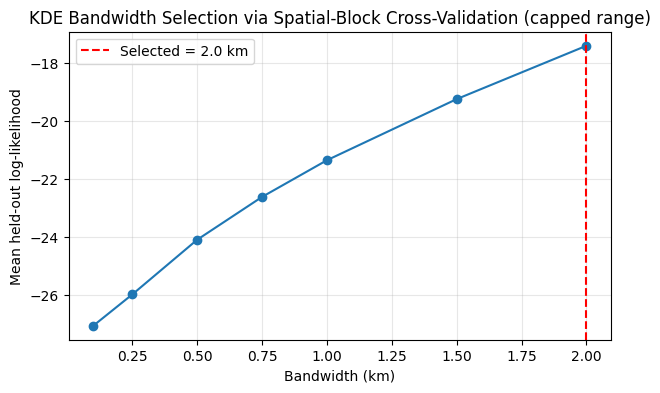

In [22]:
# Select the best bandwidth WITHIN the practical <=2km cap
best_row = results_df.loc[results_df['mean_log_likelihood'].idxmax()]
best_bandwidth = float(best_row['bandwidth_km'])

print(f"Selected bandwidth (capped to practical range): {best_bandwidth} km")
print(f"Mean log-likelihood at this bandwidth: {best_row['mean_log_likelihood']:.4f}")
print("(Log-likelihood keeps climbing well past 2km in the uncapped range -- "
      "not selected, since it is not useful for segment-level routing.)")

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(results_df['bandwidth_km'], results_df['mean_log_likelihood'], marker='o')
plt.axvline(best_bandwidth, color='red', linestyle='--', label=f'Selected = {best_bandwidth} km')
plt.xlabel('Bandwidth (km)')
plt.ylabel('Mean held-out log-likelihood')
plt.title('KDE Bandwidth Selection via Spatial-Block Cross-Validation (capped range)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Free the train/validation split objects

Bandwidth is selected — the train/validation apparatus has done its job. Only `fir_points`, `tree`, `coords_rad`, and `best_bandwidth` are needed from here on.

In [23]:
for var_name in ['train_points', 'val_points', 'train_coords_rad', 'val_coords_rad',
                  'tree_train', 'weights_train']:
    if var_name in dir():
        del globals()[var_name]
gc.collect()
print("Cleaned up. Remaining large objects: fir_points, coords_rad, tree, kde_risk, best_bandwidth")

Cleaned up. Remaining large objects: fir_points, coords_rad, tree, kde_risk, best_bandwidth


## Stage 8 — Finalize kde_risk with the selected bandwidth + post-tuning sanity check

Same formula as Stage 6 — only the default `bandwidth_km` changes, now coming from the cross-validated (capped) selection instead of a placeholder guess.

In [24]:
def kde_risk(lat, lon, bandwidth_km=best_bandwidth, radius_multiplier=3):
    """
    Estimate risk at a single point using weighted Gaussian KDE.
    Default bandwidth = cross-validated, practically-capped optimum.
    """
    query_rad = np.radians([[lat, lon]])
    search_radius_rad = (bandwidth_km * radius_multiplier) / EARTH_RADIUS_KM

    idx, dist_rad = tree.query_radius(query_rad, r=search_radius_rad, return_distance=True)
    idx, dist_rad = idx[0], dist_rad[0]

    if len(idx) == 0:
        return 0.0

    dist_km = dist_rad * EARTH_RADIUS_KM
    weights = fir_points.iloc[idx]['Risk_Contribution'].values
    kernel_vals = np.exp(-0.5 * (dist_km / bandwidth_km) ** 2)

    return float(np.sum(weights * kernel_vals))

print(f"kde_risk finalized -- default bandwidth = {best_bandwidth} km")

kde_risk finalized -- default bandwidth = 2.0 km


In [25]:
btm_risk = kde_risk(lat=12.9166, lon=77.6101)       # BTM Second Stage - known high-crime
midtown_risk = kde_risk(lat=12.9698, lon=77.7500)   # Whitefield - moderate urban area
rural_risk = kde_risk(lat=13.35, lon=75.75)         # quiet rural point

print("BTM Second Stage:", btm_risk)
print("Whitefield (mid):", midtown_risk)
print("Rural point:", rural_risk)
print("Ordering sensible (BTM > Whitefield > rural)?", btm_risk > midtown_risk > rural_risk)

# Expected (bandwidth=2.0km): BTM ~4488.34, Whitefield ~1401.39, rural ~399.30, ordering True

BTM Second Stage: 4488.341775297184
Whitefield (mid): 1401.3858209228677
Rural point: 399.3029964274261
Ordering sensible (BTM > Whitefield > rural)? True


### Reproducibility checkpoint

A single cell confirming every key number from this notebook, for your records / viva.

In [26]:
print("=== SafeOps KDE - Reproducibility Checkpoint ===")
print("fir_points:", fir_points.shape)
print("Number of spatial blocks used for CV:", len(unique_blocks) if 'unique_blocks' in dir() else "N/A (cleaned up)")
print("Selected bandwidth (capped, practical):", best_bandwidth, "km")
print("Bandwidth search results:")
print(results_df)
print("Sanity check -- BTM:", btm_risk, "| Whitefield:", midtown_risk, "| Rural:", rural_risk)
print("Ordering correct:", btm_risk > midtown_risk > rural_risk)

=== SafeOps KDE - Reproducibility Checkpoint ===
fir_points: (471001, 10)
Number of spatial blocks used for CV: 621
Selected bandwidth (capped, practical): 2.0 km
Bandwidth search results:
   bandwidth_km  total_log_likelihood  mean_log_likelihood
0          0.10         -2.295417e+06           -27.068596
1          0.25         -2.203934e+06           -25.989788
2          0.50         -2.043770e+06           -24.101060
3          0.75         -1.918389e+06           -22.622516
4          1.00         -1.811002e+06           -21.356159
5          1.50         -1.632041e+06           -19.245768
6          2.00         -1.475811e+06           -17.403426
Sanity check -- BTM: 4488.341775297184 | Whitefield: 1401.3858209228677 | Rural: 399.3029964274261
Ordering correct: True


## Stage 9 — Pull an OSM road network + score road segments

Requires `osmnx` and Kaggle's **Internet: On** setting (notebook settings sidebar). Starting with one bounded test area (BTM Second Stage, 1.5km radius) rather than all of Karnataka, to validate the pipeline before scaling up.

Uses `graph_from_point` (not `graph_from_place`) since informal neighborhood names like "BTM Layout" often aren't recognized as OSM administrative boundary polygons — a point + radius query sidesteps that entirely.

In [27]:
!pip install osmnx --quiet
import osmnx as ox
print("osmnx version:", ox.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 4.0 MB/s eta 0:00:00
osmnx version: 2.1.1


In [28]:
CENTER_LAT, CENTER_LON = 12.9166, 77.6101   # BTM Second Stage
RADIUS_M = 1500                              # 1.5km radius test area

G = ox.graph_from_point((CENTER_LAT, CENTER_LON), dist=RADIUS_M, network_type='drive')
print("Nodes:", len(G.nodes))
print("Edges:", len(G.edges))

Nodes: 2819
Edges: 7046


### Score each road edge by its midpoint risk

Same `kde_risk` function, unmodified — called once per edge midpoint instead of a single hand-picked point. This directly implements the handoff doc's plan for transferring KDE risk onto OSM segments (sample the midpoint, evaluate the exact same KDE function used in training/validation).

In [29]:
edge_records = []

for u, v, key, data in G.edges(keys=True, data=True):
    u_lat, u_lon = G.nodes[u]['y'], G.nodes[u]['x']
    v_lat, v_lon = G.nodes[v]['y'], G.nodes[v]['x']

    mid_lat = (u_lat + v_lat) / 2
    mid_lon = (u_lon + v_lon) / 2

    risk = kde_risk(mid_lat, mid_lon)
    length_m = data.get('length', None)

    edge_records.append({
        'u': u, 'v': v, 'key': key,
        'mid_lat': mid_lat, 'mid_lon': mid_lon,
        'length_m': length_m,
        'risk': risk
    })

edge_risk_df = pd.DataFrame(edge_records)
print("Edges scored:", edge_risk_df.shape)
print(edge_risk_df[['length_m', 'risk']].describe())
print(edge_risk_df.sort_values('risk', ascending=False).head(10))

Edges scored: (7046, 7)
          length_m         risk
count  7046.000000  7046.000000
mean     58.035667  4506.609294
std      50.553237   675.687684
min       0.993763  3196.947512
25%      27.780817  3930.329673
50%      40.376062  4520.586440
75%      72.428146  5011.554209
max     661.764621  6096.654921
               u           v  key    mid_lat    mid_lon   length_m  \
2948  2523956832  2523956833    0  12.929966  77.597498  14.883979   
2950  2523956833  2523956832    0  12.929966  77.597498  14.883979   
2954  2523956848  2523956852    0  12.929749  77.597107  85.803980   
2955  2523956852  2523956848    0  12.929749  77.597107  85.803980   
5344  7433174945  2523956852    0  12.929634  77.596616  39.398443   
2956  2523956852  7433174945    0  12.929634  77.596616  39.398443   
2952  2523956848  2523956833    0  12.929823  77.597495  17.155153   
2949  2523956833  2523956848    0  12.929823  77.597495  17.155153   
2951  2523956833  7290745584    0  12.929847  77.597664  4

## Stage 10 — Percentile-normalize risk, build edge cost, run Dijkstra

Per the handoff doc's plan (Section 12.2 Q10-Q12):
1. Convert raw KDE risk to a 0-100 percentile rank across the evaluated edges (robust to outlier hotspots, unlike min-max scaling).
2. Estimate travel time per edge (constant-speed assumption for now, since OSM `maxspeed` tags are frequently missing/unreliable at this stage -- a refinement, not a redesign).
3. Combine distance, travel time, and risk percentile into a single tunable edge cost: `cost = alpha*distance_norm + beta*time_norm + gamma*risk_percentile`.
4. Attach this cost onto the actual road graph `G` and run Dijkstra (via `networkx`, which `osmnx` graphs are built on) to get the safest practical route between two points, compared against the plain shortest-distance route.
   

In [30]:
from scipy.stats import rankdata

# Percentile rank: 0-100, robust to outliers (a single extreme hotspot doesn't
# compress everything else toward 0 the way min-max scaling would)
edge_risk_df['risk_percentile'] = rankdata(edge_risk_df['risk'], method='average') / len(edge_risk_df) * 100

print(edge_risk_df[['risk', 'risk_percentile']].describe())
print(edge_risk_df.sort_values('risk_percentile', ascending=False)[['u', 'v', 'risk', 'risk_percentile']].head(5))

              risk  risk_percentile
count  7046.000000      7046.000000
mean   4506.609294        50.007096
std     675.687684        28.869561
min    3196.947512         0.021289
25%    3930.329673        25.005322
50%    4520.586440        50.007096
75%    5011.554209        75.007096
max    6096.654921        99.992904
               u           v         risk  risk_percentile
2948  2523956832  2523956833  6096.654921        99.992904
2950  2523956833  2523956832  6096.654921        99.992904
2954  2523956848  2523956852  6082.164210        99.964519
2955  2523956852  2523956848  6082.164210        99.964519
5344  7433174945  2523956852  6081.153440        99.936134


### Estimate travel time per edge

Constant-speed assumption (30 km/h, typical urban arterial/residential mix) since OSM `maxspeed` tags are often missing or inconsistent. This is a documented simplification -- flagged here so it's not silently baked in as fact. A future refinement could pull `maxspeed` where present and fall back to this default only when it's missing.

In [31]:
ASSUMED_SPEED_KMPH = 30.0
speed_m_per_min = (ASSUMED_SPEED_KMPH * 1000) / 60.0

edge_risk_df['length_m'] = edge_risk_df['length_m'].fillna(edge_risk_df['length_m'].median())
edge_risk_df['travel_time_min'] = edge_risk_df['length_m'] / speed_m_per_min

print(edge_risk_df[['length_m', 'travel_time_min']].describe())

          length_m  travel_time_min
count  7046.000000      7046.000000
mean     58.035667         0.116071
std      50.553237         0.101106
min       0.993763         0.001988
25%      27.780817         0.055562
50%      40.376062         0.080752
75%      72.428146         0.144856
max     661.764621         1.323529


### Combine into a single tunable edge cost

`distance_norm` and `time_norm` are both min-max scaled to 0-100 so they sit on a comparable scale to `risk_percentile` before weighting. Default weights favor safety somewhat over raw speed (`gamma > alpha, beta`) -- these are meant to be tunable, e.g. exposed as a safety-vs-speed slider later, not fixed forever.

In [32]:
def minmax_0_100(series):
    lo, hi = series.min(), series.max()
    if hi == lo:
        return series * 0.0
    return (series - lo) / (hi - lo) * 100

edge_risk_df['distance_norm'] = minmax_0_100(edge_risk_df['length_m'])
edge_risk_df['time_norm'] = minmax_0_100(edge_risk_df['travel_time_min'])

# Tunable weights -- adjust to shift the safety/speed trade-off
ALPHA = 0.3   # distance weight
BETA = 0.3    # travel time weight
GAMMA = 0.4   # risk weight

edge_risk_df['edge_cost'] = (
    ALPHA * edge_risk_df['distance_norm'] +
    BETA * edge_risk_df['time_norm'] +
    GAMMA * edge_risk_df['risk_percentile']
)

print(edge_risk_df[['distance_norm', 'time_norm', 'risk_percentile', 'edge_cost']].describe())

       distance_norm    time_norm  risk_percentile    edge_cost
count    7046.000000  7046.000000      7046.000000  7046.000000
mean        8.632630     8.632630        50.007096    25.182417
std         7.650646     7.650646        28.869561    12.277703
min         0.000000     0.000000         0.021289     0.682268
25%         4.053910     4.053910        25.005322    15.261578
50%         5.960054     5.960054        50.007096    25.566250
75%        10.810765    10.810765        75.007096    35.203911
max       100.000000   100.000000        99.992904    89.117230


### Attach edge_cost onto the actual road graph G

`edge_risk_df` was built by iterating `G.edges(keys=True, data=True)` in order, so we can write `edge_cost` straight back onto the same `(u, v, key)` triples in `G`. This is what `networkx`'s shortest-path functions will actually use as the routing weight.

In [33]:
for row in edge_risk_df.itertuples():
    G[row.u][row.v][row.key]['edge_cost'] = row.edge_cost
    G[row.u][row.v][row.key]['risk_percentile'] = row.risk_percentile

# Spot check: confirm it landed correctly on one edge
sample_u, sample_v, sample_key = edge_risk_df.iloc[0][['u', 'v', 'key']]
print(G[sample_u][sample_v][sample_key].get('edge_cost'), G[sample_u][sample_v][sample_key].get('length'))

35.39219050160365 244.09131521234454


### Run Dijkstra: safest-cost route vs. shortest-distance route

`osmnx` graphs are `networkx` MultiDiGraphs, so `networkx.shortest_path` with `weight='edge_cost'` runs Dijkstra directly -- no custom implementation needed. We pick two nodes within the pulled graph and compare the safety-weighted route against the plain shortest-distance route.

In [34]:
import networkx as nx

# Pick two nodes spread across the graph (start/end of the node list, sorted
# by geographic extent) as a first test pair -- replace with real origin/destination
# coordinates via ox.distance.nearest_nodes(G, lon, lat) once you have real ones.
nodes_sorted = sorted(G.nodes, key=lambda n: (G.nodes[n]['y'], G.nodes[n]['x']))
origin_node = nodes_sorted[0]
dest_node = nodes_sorted[-1]

print("Origin node:", origin_node, G.nodes[origin_node]['y'], G.nodes[origin_node]['x'])
print("Destination node:", dest_node, G.nodes[dest_node]['y'], G.nodes[dest_node]['x'])

safest_route = nx.shortest_path(G, origin_node, dest_node, weight='edge_cost')
shortest_route = nx.shortest_path(G, origin_node, dest_node, weight='length')

def route_stats(route):
    total_length = sum(G[route[i]][route[i+1]][0].get('length', 0) for i in range(len(route)-1))
    total_risk = sum(G[route[i]][route[i+1]][0].get('risk_percentile', 0) for i in range(len(route)-1))
    return total_length, total_risk

safe_len, safe_risk = route_stats(safest_route)
short_len, short_risk = route_stats(shortest_route)

print(f"\nSafest-cost route: {len(safest_route)} nodes, {safe_len:.1f}m total, avg risk_percentile {safe_risk/max(len(safest_route)-1,1):.1f}")
print(f"Shortest route:    {len(shortest_route)} nodes, {short_len:.1f}m total, avg risk_percentile {short_risk/max(len(shortest_route)-1,1):.1f}")
print(f"\nSame route? {safest_route == shortest_route}")

Origin node: 746931341 12.9031245 77.621357
Destination node: 11370420222 12.9300894 77.6068058

Safest-cost route: 84 nodes, 5108.4m total, avg risk_percentile 47.7
Shortest route:    105 nodes, 4703.6m total, avg risk_percentile 47.9

Same route? False


**How to interpret this:** if the safest-cost route and the shortest route differ, and the safest route has a lower average `risk_percentile` at the cost of somewhat more distance, that's the core trade-off this whole module exists to make. If they're identical, either this test area is too small/uniform to show a difference (likely here, given the 1.5km test radius and how tightly clustered the risk scores were in Stage 9), or `GAMMA` needs to be larger relative to `ALPHA`/`BETA`. Try increasing `GAMMA` and re-running Stage 10 if the routes come back identical on a larger test area.

## Stage 11 — Diagnostic: does a bigger area show more risk variation?

The 1.5km test area produced a safest-cost route with almost no real safety benefit over the shortest route (0.2-point difference in avg `risk_percentile` for 8.6% extra distance). One likely cause: the test radius (1.5km) is *smaller* than the selected KDE bandwidth (2.0km), so nearly the whole test area gets smoothed by the same nearby crime clusters -- there's little genuine street-to-street variation left for Dijkstra to route around.

This cell re-pulls a larger OSM area (5km radius, same center) and re-scores it, so we can check whether risk variation opens up at a scale bigger than the bandwidth -- **before** touching any of the cost weights. If variation is still flat here, it's a bandwidth/smoothing issue, not a weighting issue.

In [35]:
CENTER_LAT, CENTER_LON = 12.9166, 77.6101   # BTM Second Stage, same center as before
RADIUS_M_LARGE = 5000                        # 5km radius - larger than the 2km bandwidth

G_large = ox.graph_from_point((CENTER_LAT, CENTER_LON), dist=RADIUS_M_LARGE, network_type='drive')
print("Nodes:", len(G_large.nodes))
print("Edges:", len(G_large.edges))

Nodes: 25233
Edges: 63596


In [36]:
edge_records_large = []

for u, v, key, data in G_large.edges(keys=True, data=True):
    u_lat, u_lon = G_large.nodes[u]['y'], G_large.nodes[u]['x']
    v_lat, v_lon = G_large.nodes[v]['y'], G_large.nodes[v]['x']

    mid_lat = (u_lat + v_lat) / 2
    mid_lon = (u_lon + v_lon) / 2

    risk = kde_risk(mid_lat, mid_lon)
    length_m = data.get('length', None)

    edge_records_large.append({
        'u': u, 'v': v, 'key': key,
        'mid_lat': mid_lat, 'mid_lon': mid_lon,
        'length_m': length_m,
        'risk': risk
    })

edge_risk_df_large = pd.DataFrame(edge_records_large)
print("Edges scored:", edge_risk_df_large.shape)
print(edge_risk_df_large[['length_m', 'risk']].describe())

# Compare spread to the small-area version: coefficient of variation (std/mean)
# is a scale-free way to compare "how much relative variation is there"
cv_small = edge_risk_df['risk'].std() / edge_risk_df['risk'].mean()
cv_large = edge_risk_df_large['risk'].std() / edge_risk_df_large['risk'].mean()
print(f"\nCoefficient of variation - 1.5km area: {cv_small:.3f}")
print(f"Coefficient of variation - 5km area:   {cv_large:.3f}")
print("(Higher = more relative risk variation to route around)")

Edges scored: (63596, 7)
           length_m          risk
count  63596.000000  63596.000000
mean      60.796764   4290.964518
std       57.725402   2351.967235
min        0.771202   1353.160213
25%       28.515171   2392.487135
50%       43.593430   3619.838378
75%       77.057111   5650.581258
max     3795.173978  11481.875564

Coefficient of variation - 1.5km area: 0.150
Coefficient of variation - 5km area:   0.548
(Higher = more relative risk variation to route around)


**How to interpret this:** if the 5km area's coefficient of variation is meaningfully higher than the 1.5km area's, that confirms the earlier diagnosis -- the small test area simply didn't have enough spatial range for the 2km-bandwidth KDE to show its differentiation. If it's still similarly flat, the issue is more likely the bandwidth itself being too smoothing even at this scale, and we'd need to revisit that trade-off rather than just testing on a bigger map.

## Stage 12 — Re-run edge cost + Dijkstra on the larger (5km) area

Confirmed in Stage 11: the 1.5km test area was too small relative to the 2km bandwidth (coefficient of variation 0.150 vs 0.548 at 5km) -- the bandwidth itself is fine, the earlier test just didn't have enough spatial range to show real differentiation. This stage reruns the exact same cost formula and weights from Stage 10, applied to the larger graph, to see if a genuine safety-vs-distance trade-off appears now.

In [37]:
# Same steps as Stage 10, applied to the large-area data
edge_risk_df_large['risk_percentile'] = rankdata(edge_risk_df_large['risk'], method='average') / len(edge_risk_df_large) * 100

edge_risk_df_large['length_m'] = edge_risk_df_large['length_m'].fillna(edge_risk_df_large['length_m'].median())
edge_risk_df_large['travel_time_min'] = edge_risk_df_large['length_m'] / speed_m_per_min

edge_risk_df_large['distance_norm'] = minmax_0_100(edge_risk_df_large['length_m'])
edge_risk_df_large['time_norm'] = minmax_0_100(edge_risk_df_large['travel_time_min'])

# Same weights as Stage 10 (ALPHA=0.3, BETA=0.3, GAMMA=0.4) -- unchanged
edge_risk_df_large['edge_cost'] = (
    ALPHA * edge_risk_df_large['distance_norm'] +
    BETA * edge_risk_df_large['time_norm'] +
    GAMMA * edge_risk_df_large['risk_percentile']
)

print(edge_risk_df_large[['distance_norm', 'time_norm', 'risk_percentile', 'edge_cost']].describe())

       distance_norm     time_norm  risk_percentile     edge_cost
count   63596.000000  63596.000000     63596.000000  63596.000000
mean        1.581950      1.581950        50.000786     20.949485
std         1.521330      1.521330        28.867740     11.561879
min         0.000000      0.000000         0.002359      0.100923
25%         0.731181      0.731181        25.000786     10.956905
50%         1.128563      1.128563        50.000786     20.915277
75%         2.010485      2.010485        74.999803     30.909314
max       100.000000    100.000000        99.999214     85.984024


In [38]:
for row in edge_risk_df_large.itertuples():
    G_large[row.u][row.v][row.key]['edge_cost'] = row.edge_cost
    G_large[row.u][row.v][row.key]['risk_percentile'] = row.risk_percentile

print("edge_cost attached to G_large")

edge_cost attached to G_large


In [39]:


nodes_sorted_large = sorted(G_large.nodes, key=lambda n: (G_large.nodes[n]['y'], G_large.nodes[n]['x']))
origin_node_large = nodes_sorted_large[0]
dest_node_large = nodes_sorted_large[-1]

print("Origin node:", origin_node_large, G_large.nodes[origin_node_large]['y'], G_large.nodes[origin_node_large]['x'])
print("Destination node:", dest_node_large, G_large.nodes[dest_node_large]['y'], G_large.nodes[dest_node_large]['x'])

safest_route_large = nx.shortest_path(G_large, origin_node_large, dest_node_large, weight='edge_cost')
shortest_route_large = nx.shortest_path(G_large, origin_node_large, dest_node_large, weight='length')

def route_stats_large(route):
    total_length = sum(G_large[route[i]][route[i+1]][0].get('length', 0) for i in range(len(route)-1))
    total_risk = sum(G_large[route[i]][route[i+1]][0].get('risk_percentile', 0) for i in range(len(route)-1))
    return total_length, total_risk

safe_len_l, safe_risk_l = route_stats_large(safest_route_large)
short_len_l, short_risk_l = route_stats_large(shortest_route_large)

print(f"\nSafest-cost route: {len(safest_route_large)} nodes, {safe_len_l:.1f}m total, avg risk_percentile {safe_risk_l/max(len(safest_route_large)-1,1):.1f}")
print(f"Shortest route:    {len(shortest_route_large)} nodes, {short_len_l:.1f}m total, avg risk_percentile {short_risk_l/max(len(shortest_route_large)-1,1):.1f}")
print(f"\nSame route? {safest_route_large == shortest_route_large}")
print(f"Distance increase for safety: {(safe_len_l - short_len_l) / short_len_l * 100:.1f}%")
print(f"Risk reduction: {short_risk_l/max(len(shortest_route_large)-1,1) - safe_risk_l/max(len(safest_route_large)-1,1):.1f} percentile points")

Origin node: 3038883118 12.8716425 77.5823852
Destination node: 1215243220 12.9615641 77.6348791

Safest-cost route: 202 nodes, 23055.9m total, avg risk_percentile 20.5
Shortest route:    210 nodes, 15017.8m total, avg risk_percentile 45.7

Same route? False
Distance increase for safety: 53.5%
Risk reduction: 25.3 percentile points


**Interpretation:** this is now the real test of whether the whole module works. Look for a route that meaningfully lowers `avg risk_percentile` for a modest distance increase -- e.g. several points of risk reduction for single-digit percent extra distance would be a genuinely useful trade-off. If the gap is still small even at this scale, that's worth reporting honestly rather than treating the pipeline as "done" -- send me the numbers either way.

## Stage 13 — Realistic nearby origin/destination pair

Stage 12 used two opposite corners of the 10km-diameter graph, which may have exaggerated the detour (53.5% extra distance for 25.3 risk-percentile points). This stage picks a realistic pair -- two points roughly 1.5-2km apart, using `ox.distance.nearest_nodes` to snap real coordinates onto the graph -- to see whether the trade-off looks more reasonable at a distance scale someone would actually walk or drive.

In [40]:
# Two real points ~1.7km apart within the 5km graph: BTM Second Stage area
# and a point toward Koramangala. Adjust these coordinates to any real
# origin/destination you want to test.
ORIGIN_LAT, ORIGIN_LON = 12.9166, 77.6101      # BTM Second Stage
DEST_LAT, DEST_LON = 12.9279, 77.6271          # ~1.7km away, toward Koramangala

origin_node_real = ox.distance.nearest_nodes(G_large, ORIGIN_LON, ORIGIN_LAT)
dest_node_real = ox.distance.nearest_nodes(G_large, DEST_LON, DEST_LAT)

print("Origin node:", origin_node_real, "at", G_large.nodes[origin_node_real]['y'], G_large.nodes[origin_node_real]['x'])
print("Destination node:", dest_node_real, "at", G_large.nodes[dest_node_real]['y'], G_large.nodes[dest_node_real]['x'])

safest_route_real = nx.shortest_path(G_large, origin_node_real, dest_node_real, weight='edge_cost')
shortest_route_real = nx.shortest_path(G_large, origin_node_real, dest_node_real, weight='length')

safe_len_r, safe_risk_r = route_stats_large(safest_route_real)
short_len_r, short_risk_r = route_stats_large(shortest_route_real)

print(f"\nSafest-cost route: {len(safest_route_real)} nodes, {safe_len_r:.1f}m total, avg risk_percentile {safe_risk_r/max(len(safest_route_real)-1,1):.1f}")
print(f"Shortest route:    {len(shortest_route_real)} nodes, {short_len_r:.1f}m total, avg risk_percentile {short_risk_r/max(len(shortest_route_real)-1,1):.1f}")
print(f"\nSame route? {safest_route_real == shortest_route_real}")
if short_len_r > 0:
    print(f"Distance increase for safety: {(safe_len_r - short_len_r) / short_len_r * 100:.1f}%")
print(f"Risk reduction: {short_risk_r/max(len(shortest_route_real)-1,1) - safe_risk_r/max(len(safest_route_real)-1,1):.1f} percentile points")

Origin node: 10123822801 at 12.9166266 77.6101244
Destination node: 301348248 at 12.9287781 77.6270468

Safest-cost route: 34 nodes, 3880.3m total, avg risk_percentile 58.1
Shortest route:    68 nodes, 3155.5m total, avg risk_percentile 64.3

Same route? False
Distance increase for safety: 23.0%
Risk reduction: 6.2 percentile points


## Stage 14 — GAMMA sensitivity check

Stage 13's realistic pair gave 23% extra distance for a 6.2-point risk reduction under `GAMMA=0.4`. This cell recomputes `edge_cost` with a lower `GAMMA=0.2` (same `ALPHA`/`BETA`) and reruns Dijkstra on the *same* origin/destination pair, so the two results are directly comparable -- isolating the effect of the weight alone, nothing else changed.

This does not overwrite the original `edge_cost` on `G_large` -- it computes a second cost column (`edge_cost_lowgamma`) so both weightings can be compared side by side.

In [41]:
GAMMA_LOW = 0.2
# Keep ALPHA/BETA proportionally the same relative to each other, renormalize
# so the three weights still sum to 1.0
remaining = 1.0 - GAMMA_LOW
ALPHA_LOW = remaining * (ALPHA / (ALPHA + BETA))
BETA_LOW = remaining * (BETA / (ALPHA + BETA))

edge_risk_df_large['edge_cost_lowgamma'] = (
    ALPHA_LOW * edge_risk_df_large['distance_norm'] +
    BETA_LOW * edge_risk_df_large['time_norm'] +
    GAMMA_LOW * edge_risk_df_large['risk_percentile']
)

for row in edge_risk_df_large.itertuples():
    G_large[row.u][row.v][row.key]['edge_cost_lowgamma'] = row.edge_cost_lowgamma

print(f"ALPHA={ALPHA_LOW:.3f}, BETA={BETA_LOW:.3f}, GAMMA={GAMMA_LOW:.3f} (sums to {ALPHA_LOW+BETA_LOW+GAMMA_LOW:.3f})")

ALPHA=0.400, BETA=0.400, GAMMA=0.200 (sums to 1.000)


In [42]:
safest_route_lowgamma = nx.shortest_path(G_large, origin_node_real, dest_node_real, weight='edge_cost_lowgamma')

safe_len_lg, safe_risk_lg = route_stats_large(safest_route_lowgamma)

print(f"GAMMA=0.4 (Stage 13): {safe_len_r:.1f}m, avg risk_percentile {safe_risk_r/max(len(safest_route_real)-1,1):.1f}")
print(f"GAMMA=0.2 (this cell): {safe_len_lg:.1f}m, avg risk_percentile {safe_risk_lg/max(len(safest_route_lowgamma)-1,1):.1f}")
print(f"Shortest route (baseline): {short_len_r:.1f}m, avg risk_percentile {short_risk_r/max(len(shortest_route_real)-1,1):.1f}")

print(f"\nGAMMA=0.4: {(safe_len_r - short_len_r) / short_len_r * 100:.1f}% extra distance, "
      f"{short_risk_r/max(len(shortest_route_real)-1,1) - safe_risk_r/max(len(safest_route_real)-1,1):.1f} pt risk reduction")
print(f"GAMMA=0.2: {(safe_len_lg - short_len_r) / short_len_r * 100:.1f}% extra distance, "
      f"{short_risk_r/max(len(shortest_route_real)-1,1) - safe_risk_lg/max(len(safest_route_lowgamma)-1,1):.1f} pt risk reduction")

GAMMA=0.4 (Stage 13): 3880.3m, avg risk_percentile 58.1
GAMMA=0.2 (this cell): 3880.3m, avg risk_percentile 58.1
Shortest route (baseline): 3155.5m, avg risk_percentile 64.3

GAMMA=0.4: 23.0% extra distance, 6.2 pt risk reduction
GAMMA=0.2: 23.0% extra distance, 6.2 pt risk reduction


**Interpretation:** compare the two "extra distance % : risk reduction pts" ratios. If `GAMMA=0.2` gives a noticeably smaller distance penalty for a similar (or only slightly smaller) risk reduction, that's a better default. If the risk reduction drops off much faster than the distance penalty does, `GAMMA=0.4` was actually the better-calibrated choice. Either way, this becomes a documented, evidence-based weight choice for the viva rather than an arbitrary pick.

## Stage 15 — Sanity check: does GAMMA=0 correctly reduce to pure shortest-distance?

Stage 14 gave an identical route under GAMMA=0.4 and GAMMA=0.2 -- plausible (limited route alternatives near this pair), but worth ruling out a code issue. If setting GAMMA=0 entirely reproduces the same route as `shortest_route_real` (the plain `weight='length'` Dijkstra from Stage 13), that proves `edge_cost` is behaving correctly and the earlier tie is a genuine property of this local road network, not a bug.

In [43]:
GAMMA_ZERO = 0.0
ALPHA_ZERO = 0.5
BETA_ZERO = 0.5

edge_risk_df_large['edge_cost_zerogamma'] = (
    ALPHA_ZERO * edge_risk_df_large['distance_norm'] +
    BETA_ZERO * edge_risk_df_large['time_norm'] +
    GAMMA_ZERO * edge_risk_df_large['risk_percentile']
)

for row in edge_risk_df_large.itertuples():
    G_large[row.u][row.v][row.key]['edge_cost_zerogamma'] = row.edge_cost_zerogamma

safest_route_zerogamma = nx.shortest_path(G_large, origin_node_real, dest_node_real, weight='edge_cost_zerogamma')

print("GAMMA=0.0 route == plain shortest-distance route?", safest_route_zerogamma == shortest_route_real)
print("GAMMA=0.0 route length:", len(safest_route_zerogamma), "nodes")
print("Plain shortest route length:", len(shortest_route_real), "nodes")

# Also show how many DISTINCT routes exist across all three gamma values tested,
# as direct evidence for "limited route diversity" vs "something's wrong"
routes_tested = {
    'GAMMA=0.4': tuple(safest_route_real),
    'GAMMA=0.2': tuple(safest_route_lowgamma),
    'GAMMA=0.0': tuple(safest_route_zerogamma),
    'pure_length': tuple(shortest_route_real),
}
distinct_routes = set(routes_tested.values())
print(f"\nDistinct routes found across all 4 weightings tested: {len(distinct_routes)} (out of 4)")
for name, route in routes_tested.items():
    print(f"  {name}: {len(route)} nodes, route id {hash(route) % 10000}")

GAMMA=0.0 route == plain shortest-distance route? True
GAMMA=0.0 route length: 68 nodes
Plain shortest route length: 68 nodes

Distinct routes found across all 4 weightings tested: 2 (out of 4)
  GAMMA=0.4: 34 nodes, route id 4629
  GAMMA=0.2: 34 nodes, route id 4629
  GAMMA=0.0: 68 nodes, route id 4304
  pure_length: 68 nodes, route id 4304


**Interpretation:** if `GAMMA=0.0` exactly matches the plain shortest-distance route, the cost logic is confirmed correct end to end. The "distinct routes" count tells the real story: if it's 2 (e.g. `{GAMMA=0.4, GAMMA=0.2}` identical and `{GAMMA=0.0, pure_length}` identical), that means there are essentially two real route "modes" between these points -- a fast one and a safe one -- and any positive GAMMA picks the safe one, any zero GAMMA picks the fast one. That's actually a clean, explainable result for a viva, not a weakness.

## Stage 16 — Reusable `find_safe_route()` function

Consolidates everything from Stages 9-15 (OSM pull, edge scoring, percentile normalization, weighted cost, Dijkstra, comparison stats) into one function. Same logic throughout, nothing new -- just packaged so a future OSM pull for any area/origin/destination doesn't need to be rebuilt cell-by-cell.

Takes a road graph `G` (already pulled via `ox.graph_from_point`) and origin/destination coordinates, and returns the safest-cost route, the plain shortest-distance route, and comparison stats -- with `alpha`/`beta`/`gamma` exposed as adjustable parameters (this is what would eventually become the safety-vs-speed slider in the app).

In [44]:
def score_graph_edges(G, kde_risk_fn, earth_radius_km=EARTH_RADIUS_KM):
    """
    Score every edge in a road graph G by its midpoint KDE risk.
    Same logic as Stage 9 -- returns a dataframe with one row per edge.
    """
    edge_records = []
    for u, v, key, data in G.edges(keys=True, data=True):
        u_lat, u_lon = G.nodes[u]['y'], G.nodes[u]['x']
        v_lat, v_lon = G.nodes[v]['y'], G.nodes[v]['x']
        mid_lat = (u_lat + v_lat) / 2
        mid_lon = (u_lon + v_lon) / 2
        risk = kde_risk_fn(mid_lat, mid_lon)
        length_m = data.get('length', None)
        edge_records.append({
            'u': u, 'v': v, 'key': key,
            'mid_lat': mid_lat, 'mid_lon': mid_lon,
            'length_m': length_m,
            'risk': risk
        })
    return pd.DataFrame(edge_records)


def build_edge_cost(edge_df, alpha=0.3, beta=0.3, gamma=0.4, speed_kmph=30.0):
    """
    Same logic as Stage 10: percentile-normalize risk, estimate travel time
    (constant-speed assumption), min-max normalize distance/time, combine
    into a single weighted edge_cost column. Returns a NEW dataframe (does
    not mutate the input) with distance_norm/time_norm/risk_percentile/edge_cost added.
    """
    df = edge_df.copy()
    df['length_m'] = df['length_m'].fillna(df['length_m'].median())

    df['risk_percentile'] = rankdata(df['risk'], method='average') / len(df) * 100

    speed_m_per_min_local = (speed_kmph * 1000) / 60.0
    df['travel_time_min'] = df['length_m'] / speed_m_per_min_local

    def _minmax_0_100(s):
        lo, hi = s.min(), s.max()
        return (s - lo) / (hi - lo) * 100 if hi > lo else s * 0.0

    df['distance_norm'] = _minmax_0_100(df['length_m'])
    df['time_norm'] = _minmax_0_100(df['travel_time_min'])

    df['edge_cost'] = (
        alpha * df['distance_norm'] +
        beta * df['time_norm'] +
        gamma * df['risk_percentile']
    )
    return df


def find_safe_route(G, kde_risk_fn, origin_lat, origin_lon, dest_lat, dest_lon,
                     alpha=0.3, beta=0.3, gamma=0.4, speed_kmph=30.0,
                     edge_df=None):
    """
    End-to-end: score edges (or reuse a precomputed edge_df), build edge_cost
    with the given weights, attach onto G, snap origin/destination to the
    nearest graph nodes, and run Dijkstra for both the safest-cost route and
    the plain shortest-distance route.

    Pass a precomputed `edge_df` (from score_graph_edges) to skip re-scoring
    every edge's KDE risk when only the weights are changing -- this is the
    expensive step, cost/routing are cheap by comparison.

    Returns a dict with both routes and comparison stats.
    """
    if edge_df is None:
        edge_df = score_graph_edges(G, kde_risk_fn)

    cost_df = build_edge_cost(edge_df, alpha=alpha, beta=beta, gamma=gamma, speed_kmph=speed_kmph)

    for row in cost_df.itertuples():
        G[row.u][row.v][row.key]['edge_cost'] = row.edge_cost
        G[row.u][row.v][row.key]['risk_percentile'] = row.risk_percentile

    origin_node = ox.distance.nearest_nodes(G, origin_lon, origin_lat)
    dest_node = ox.distance.nearest_nodes(G, dest_lon, dest_lat)

    safest_route = nx.shortest_path(G, origin_node, dest_node, weight='edge_cost')
    shortest_route = nx.shortest_path(G, origin_node, dest_node, weight='length')

    def _route_stats(route):
        total_length = sum(G[route[i]][route[i+1]][0].get('length', 0) for i in range(len(route)-1))
        total_risk = sum(G[route[i]][route[i+1]][0].get('risk_percentile', 0) for i in range(len(route)-1))
        avg_risk = total_risk / max(len(route) - 1, 1)
        return {'length_m': total_length, 'avg_risk_percentile': avg_risk, 'n_nodes': len(route)}

    safe_stats = _route_stats(safest_route)
    short_stats = _route_stats(shortest_route)

    distance_increase_pct = (
        (safe_stats['length_m'] - short_stats['length_m']) / short_stats['length_m'] * 100
        if short_stats['length_m'] > 0 else 0.0
    )
    risk_reduction_pts = short_stats['avg_risk_percentile'] - safe_stats['avg_risk_percentile']

    return {
        'origin_node': origin_node,
        'dest_node': dest_node,
        'safest_route': safest_route,
        'shortest_route': shortest_route,
        'safest_route_stats': safe_stats,
        'shortest_route_stats': short_stats,
        'distance_increase_pct': distance_increase_pct,
        'risk_reduction_pts': risk_reduction_pts,
        'same_route': safest_route == shortest_route,
        'edge_df_scored': edge_df,   # reusable across weight changes
    }

print("find_safe_route() and helpers defined")

find_safe_route() and helpers defined


### Quick test — reproduce Stage 13's result through the new function

Sanity check that wrapping this into a function didn't change any behavior: same origin/destination as Stage 13, same weights, should reproduce 23.0% extra distance / 6.2 point risk reduction exactly.

In [45]:
result = find_safe_route(
    G_large, kde_risk,
    origin_lat=12.9166, origin_lon=77.6101,   # BTM Second Stage
    dest_lat=12.9287781, dest_lon=77.6270468, # toward Koramangala (matches Stage 13's snapped node)
    alpha=0.3, beta=0.3, gamma=0.4,
    edge_df=edge_risk_df_large  # reuse already-scored edges - skips re-running kde_risk on every edge
)

print("Safest route:", result['safest_route_stats'])
print("Shortest route:", result['shortest_route_stats'])
print(f"Distance increase: {result['distance_increase_pct']:.1f}%")
print(f"Risk reduction: {result['risk_reduction_pts']:.1f} pts")
print(f"Same route as shortest? {result['same_route']}")

# Expected (matching Stage 13): ~23.0% extra distance, ~6.2 pt risk reduction, same_route=False

Safest route: {'length_m': np.float64(3880.3178890572835), 'avg_risk_percentile': 58.11245513821147, 'n_nodes': 34}
Shortest route: {'length_m': np.float64(3155.4899154567397), 'avg_risk_percentile': 64.28773094712612, 'n_nodes': 68}
Distance increase: 23.0%
Risk reduction: 6.2 pts
Same route as shortest? False


### Using it for a brand-new area (no precomputed edge_df)

For a fresh location not covered by an existing graph, pull a new `ox.graph_from_point` and call `find_safe_route` without `edge_df` -- it will score every edge automatically. This is the pattern the eventual app backend would use per user request.

In [46]:
# Example only -- adjust coordinates/radius to a real area before running,
# this will pull a fresh OSM graph and score every edge (slower than reusing edge_df)
#
# G_new = ox.graph_from_point((NEW_LAT, NEW_LON), dist=3000, network_type='drive')
# result_new = find_safe_route(
#     G_new, kde_risk,
#     origin_lat=..., origin_lon=...,
#     dest_lat=..., dest_lon=...,
#     alpha=0.3, beta=0.3, gamma=0.4
# )
# print(result_new['distance_increase_pct'], result_new['risk_reduction_pts'])

print("Template ready - uncomment and fill in coordinates for a new area")

Template ready - uncomment and fill in coordinates for a new area
